In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [31]:
data = pd.read_csv("U_of_DE_Comp.csv")
y = data["bad_flg_90plus_24m"]
X = data.drop(columns="bad_flg_90plus_24m")
data.head()


,Acct1,Acct2,Acct3,Acct4,Acct5,Acct6,Acct7,Acct8,Acct9,Acct10,...,line_12m,line_24m,PubRec1,Repo1,Score1,Score2,Util1,Util2,Util3,Util4
0,83,1,2,0,204,1,89,0,1,1,...,1000,1000,0,0,715,689,40,60,40,13
1,83,3,19,0,205,17,96,0,0,0,...,19500,19500,0,0,654,668,73,56,89,9
2,84,9,15,2,123,12,68,0,0,0,...,1000,1000,0,0,627,626,75,76,81,12
3,84,9,16,0,204,25,82,0,0,2,...,11000,11000,0,0,730,722,34,93,17,11
4,83,1,4,0,196,1,100,0,0,2,...,10000,10000,0,0,794,808,5,8,6,8


# Get rid of highly correlated values

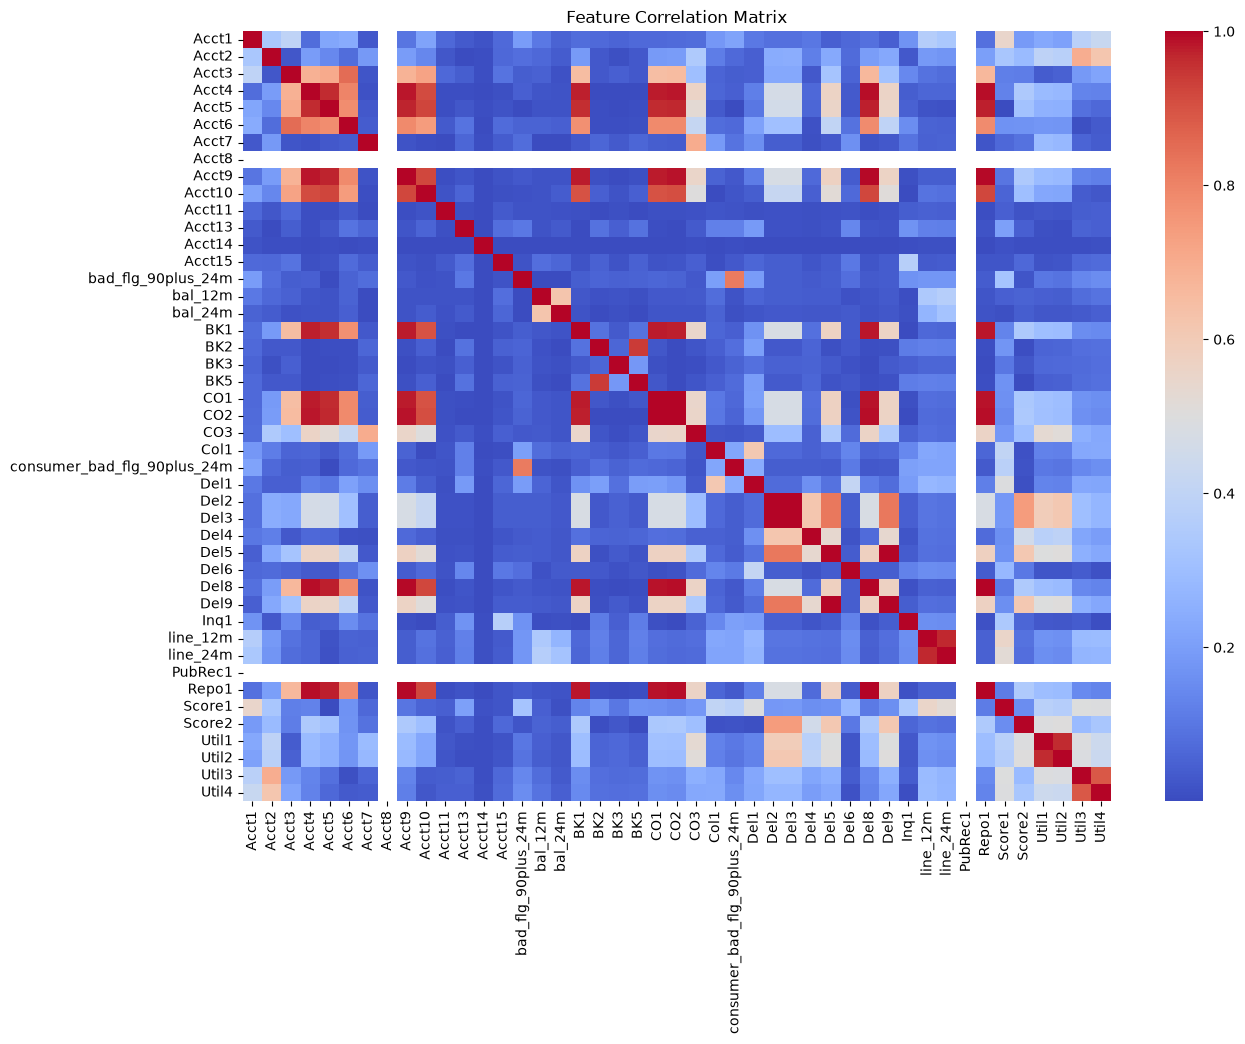

features remaining: 29


In [32]:
### CORRELAATION COEFFICIENT CUTTOFF
cuttoff = 0.75

#corr matrix and heatmap
corr_matrix = data.corr(numeric_only=True).abs()
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0.5)
plt.title("Feature Correlation Matrix")
plt.show()


upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper.columns if any(upper[column] > cuttoff)]
data_reduced = data.drop(columns=to_drop)

print("features remaining:", data_reduced.shape[1])

# Selecting the most predictive features using SelectKBest

In [ ]:
### NUM FEATURES YOU WANT REMAINING
num = 5

from sklearn.feature_selection import SelectKBest, f_classif
X = data_reduced
X = pd.get_dummies(X, drop_first=True)

selector = SelectKBest(score_func=f_classif, k=num)
X_selected = selector.fit_transform(X, y)

selected_features = X.columns[selector.get_support()]

df_selected = X[selected_features].copy()
df_selected["bad_flg_90plus_24m"] = y

df_selected.head()

/opt/miniconda3/envs/bhdac/lib/python3.14/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [ 5 10 23] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/opt/miniconda3/envs/bhdac/lib/python3.14/site-packages/sklearn/feature_selection/_univariate_selection.py:111: RuntimeWarning: divide by zero encountered in divide
  f = msb / msw
/opt/miniconda3/envs/bhdac/lib/python3.14/site-packages/sklearn/feature_selection/_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


,Acct1,bad_flg_90plus_24m,Col1,Del1,Score1
0,83,0,0,1,715
1,83,0,0,1,654
2,84,0,0,6,627
3,84,0,0,6,730
4,83,0,0,0,794
